# Accessing GPM data with EarthAccess


[EarthAccess](https://earthaccess.readthedocs.io/) is a NASA library for
searching and accessing Earthdata granules. It can be used together with
GPM-API in two ways:

* **Download first, then open locally.** EarthAccess downloads the selected
  granules to a local directory and GPM-API opens them from disk.
* **Stream directly from the cloud.** EarthAccess returns file-like objects
  backed by HTTP or cloud storage. GPM-API reads these objects without
  creating local copies.

In both cases, **GPM-API converts the source files into analysis-ready
``xarray.DataTree`` objects**.

### Prerequisites

Install EarthAccess in the environment where the tutorial is executed: ``pip install earthaccess``

You also need an Earthdata Login account. Configure EarthAccess authentication
according to the [EarthAccess authentication guide](
https://earthaccess.readthedocs.io/en/latest/user/reference/auth).

GPM-API can create the ``.netrc`` file used by
EarthAccess when configuring its EarthData credentials (see [GPM-API Quick Start](https://gpm-api.readthedocs.io/en/latest/03_quickstart.html#register-to-the-nasa-ges-disc)).

## 1. Imports and authentication

In [ ]:
from pathlib import Path

import earthaccess
import matplotlib.pyplot as plt

import gpm

# Authenticate with NASA Earthdata.
# With a configured .netrc file, EarthAccess can authenticate non-interactively.
# If you defined the GPM-API configuration file and specified the EarthData credientials,
#  the .netrc has been already created by GPM-API.
earthaccess.login()


## 2. Searching for granules

EarthAccess searches NASA collection short names, whereas GPM-API identifies
products with concise product acronyms such as ``"1C-GMI-R"`` or
``"IMERG-FR"``. 

Use `gpm.get_nasa_collection_shortname` to translate between these two naming systems.

You can inspect the available GPM-API products and the temporal coverage of a
specific product before searching:

In [ ]:
# List all product acronyms known to GPM-API.
print("Available GPM-API products:")
print(gpm.available_products())

# Define product and get its short name and available time range.
product = "1C-GMI-R"
short_name = gpm.get_nasa_collection_shortname(product)
product_start = gpm.get_product_start_time(product)
product_end = gpm.get_product_end_time(product)

print(f"EarthAccess collection: {short_name}")
print(f"Available from {product_start} to {product_end}")

Available GPM-API products:
['1A-GMI', '1A-TMI', '1B-GMI', '1B-Ka', '1B-Ku', '1B-PR', '1B-TMI', '1C-AMSR2-GCOMW1', '1C-AMSRE-AQUA', '1C-AMSUB-NOAA15', '1C-AMSUB-NOAA16', '1C-AMSUB-NOAA17', '1C-ATMS-NOAA20', '1C-ATMS-NOAA21', '1C-ATMS-NPP', '1C-GMI', '1C-GMI-R', '1C-MHS-METOPA', '1C-MHS-METOPB', '1C-MHS-METOPC', '1C-MHS-NOAA18', '1C-MHS-NOAA19', '1C-SAPHIR-MT1', '1C-SSMI-F08', '1C-SSMI-F10', '1C-SSMI-F11', '1C-SSMI-F13', '1C-SSMI-F14', '1C-SSMI-F15', '1C-SSMIS-F16', '1C-SSMIS-F17', '1C-SSMIS-F18', '1C-SSMIS-F19', '1C-TMI', '2A-AMSR2-GCOMW1', '2A-AMSR2-GCOMW1-CLIM', '2A-AMSRE-AQUA-CLIM', '2A-AMSUB-NOAA15-CLIM', '2A-AMSUB-NOAA16-CLIM', '2A-AMSUB-NOAA17-CLIM', '2A-ATMS-NOAA20', '2A-ATMS-NOAA20-CLIM', '2A-ATMS-NOAA21', '2A-ATMS-NOAA21-CLIM', '2A-ATMS-NPP', '2A-ATMS-NPP-CLIM', '2A-DPR', '2A-ENV-DPR', '2A-ENV-Ka', '2A-ENV-Ku', '2A-ENV-PR', '2A-GMI', '2A-GMI-CLIM', '2A-GPM-SLH', '2A-Ka', '2A-Ku', '2A-MHS-METOPA', '2A-MHS-METOPA-CLIM', '2A-MHS-METOPB', '2A-MHS-METOPB-CLIM', '2A-MHS-METOPC', '2A

The ``version`` argument is a string in EarthAccess searches. The bounding
box selects granules intersecting the area; it does **not** crop the contents
of the downloaded files.

In [ ]:
version = "07"
bounding_box = (0, 30, 10, 40)  # lon_min, lat_min, lon_max, lat_max

results = earthaccess.search_data(
    short_name=short_name,
    version=version,
    bounding_box=bounding_box,
    temporal=("2019-01-01", "2019-02-10"),
    count=3,  # Limit the number of results to 5
)
print(results)

[Collection: {'ShortName': 'GPM_1CGPMGMI_R', 'Version': '07'}
Spatial coverage: {'HorizontalSpatialDomain': {'Geometry': {'GPolygons': [{'Boundary': {'Points': [{'Longitude': -107.89544, 'Latitude': -69.35692}, {'Longitude': -69.49997, 'Latitude': -66.88645}, {'Longitude': -77.24578, 'Latitude': -58.64768}, {'Longitude': -105.4037, 'Latitude': -60.46447}, {'Longitude': -107.89544, 'Latitude': -69.35692}]}}, {'Boundary': {'Points': [{'Longitude': -69.90841, 'Latitude': -66.95179}, {'Longitude': -45.58746, 'Latitude': -57.87594}, {'Longitude': -56.36403, 'Latitude': -51.46498}, {'Longitude': -78.02402, 'Latitude': -58.81552}, {'Longitude': -69.90841, 'Latitude': -66.95179}]}}, {'Boundary': {'Points': [{'Longitude': -45.85605, 'Latitude': -57.99388}, {'Longitude': -32.41011, 'Latitude': -46.19672}, {'Longitude': -42.5823, 'Latitude': -41.23973}, {'Longitude': -56.84867, 'Latitude': -51.76527}, {'Longitude': -45.85605, 'Latitude': -57.99388}]}}, {'Boundary': {'Points': [{'Longitude': -32.6

## 3. Download and open files locally

Download the search results with EarthAccess, then pass the returned local
paths directly to `gpm.open_files`:

In [ ]:
download_directory = Path.home() / "Downloads"
filepaths = earthaccess.download(results, download_directory)

# GPM-API opens and concatenates the downloaded granules.
dt = gpm.open_files(filepaths)
dt

QUEUEING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/3 [00:00<?, ?it/s]

/home/ghiggi/Python_Packages/gpm_api/gpm/dataset/dataset.py:633: GPM_Warning: 'Presence of non-contiguous scans !'
  scan_mode: finalize_dataset(
/home/ghiggi/Python_Packages/gpm_api/gpm/dataset/dataset.py:633: GPM_Warning: 'Presence of invalid geolocation coordinates !'
  scan_mode: finalize_dataset(
/home/ghiggi/Python_Packages/gpm_api/gpm/dataset/dataset.py:633: GPM_Warning: 'Presence of non-contiguous scans !'
  scan_mode: finalize_dataset(


<xarray.DataTree>
Group: /
├── Group: /S1
│       Dimensions:                  (cross_track: 221, along_track: 8885,
│                                     pmw_frequency: 9)
│       Coordinates:
│           gpm_cross_track_id       (cross_track) int64 2kB 0 1 2 3 ... 217 218 219 220
│           sunLocalTime             (cross_track, along_track) float32 8MB dask.array<chunksize=(221, 2962), meta=np.ndarray>
│           Quality                  (cross_track, along_track) float32 8MB dask.array<chunksize=(221, 2962), meta=np.ndarray>
│           SCorientation            (along_track) float32 36kB dask.array<chunksize=(2962,), meta=np.ndarray>
│           lon                      (cross_track, along_track) float32 8MB -100.6 .....
│           lat                      (cross_track, along_track) float32 8MB -60.83 .....
│           time                     (along_track) datetime64[us] 71kB 2019-01-01T04:...
│           gpm_id                   (along_track) <U10 355kB '27513-0' ... '27519-2961'
│           gpm_granule_id           (along_track) int64 71kB 27513 27513 ... 27519
│           gpm_along_track_id       (along_track) int64 71kB 0 1 2 3 ... 2959 2960 2961
│         * pmw_frequency            (pmw_frequency) <U3 108B '10V' '10H' ... '89H'
│           crsWGS84                 int64 8B 0
│       Dimensions without coordinates: cross_track, along_track
│       Data variables:
│           incidenceAngle           (cross_track, along_track, pmw_frequency) float32 71MB dask.array<chunksize=(221, 329, 9), meta=np.ndarray>
│           sunGlintAngle            (cross_track, along_track, pmw_frequency) float32 71MB dask.array<chunksize=(221, 329, 9), meta=np.ndarray>
│           Tc                       (cross_track, along_track, pmw_frequency) float32 71MB dask.array<chunksize=(221, 2962, 9), meta=np.ndarray>
│           SClatitude               (along_track) float32 36kB dask.array<chunksize=(2962,), meta=np.ndarray>
│           SClongitude              (along_track) float32 36kB dask.array<chunksize=(2962,), meta=np.ndarray>
│           SCaltitude               (along_track) float32 36kB dask.array<chunksize=(2962,), meta=np.ndarray>
│           FractionalGranuleNumber  (along_track) float64 71kB dask.array<chunksize=(2962,), meta=np.ndarray>
│       Attributes: (12/17)
│           FileName:           1C-R.GPM.GMI.XCAL2016-C.20190101-S045227-E062459.0275...
│           EphemerisFileName:  GPMCORE.20190101.045227311_20190101.062500230.001.EPH...
│           AttitudeFileName:   GPMCORE.20190101.045227311_20190101.062500230.001.ATT...
│           MissingData:        0
│           DOI:                10.5067/GPM/GMI/R/1C/07
│           DOIauthority:       http://dx.doi.org/
│           ...                 ...
│           ProcessingSystem:   PPS
│           DataFormatVersion:  7e
│           MetadataVersion:    7e
│           ScanMode:           S1
│           gpm_api_product:    1C-GMI-R
│           history:            Created by ghiggi/gpm_api software on 2026-11-02 17:3...
└── Group: /S2
        Dimensions:                  (cross_track: 221, along_track: 8885,
                                      pmw_frequency: 4)
        Coordinates:
            gpm_cross_track_id       (cross_track) int64 2kB 0 1 2 3 ... 217 218 219 220
            sunLocalTime             (cross_track, along_track) float32 8MB dask.array<chunksize=(221, 2962), meta=np.ndarray>
            Quality                  (cross_track, along_track) float32 8MB dask.array<chunksize=(221, 2962), meta=np.ndarray>
            SCorientation            (along_track) float32 36kB dask.array<chunksize=(2962,), meta=np.ndarray>
            lon                      (cross_track, along_track) float32 8MB nan ... nan
            lat                      (cross_track, along_track) float32 8MB nan ... nan
            time                     (along_track) datetime64[us] 71kB 2019-01-01T04:...
            gpm_id                   (along_track) <U10 355kB '27513-0' ... '27519-2961'
    

The returned object is a ``DataTree``. For this swath example, the ``S1``
group contains the analysis-ready GMI data:

In [ ]:
ds = dt["S1"].to_dataset()
ds

<xarray.Dataset> Size: 244MB
Dimensions:                  (cross_track: 221, along_track: 8885,
                              pmw_frequency: 9)
Coordinates:
    gpm_cross_track_id       (cross_track) int64 2kB 0 1 2 3 ... 217 218 219 220
    sunLocalTime             (cross_track, along_track) float32 8MB dask.array<chunksize=(221, 2962), meta=np.ndarray>
    Quality                  (cross_track, along_track) float32 8MB dask.array<chunksize=(221, 2962), meta=np.ndarray>
    SCorientation            (along_track) float32 36kB dask.array<chunksize=(2962,), meta=np.ndarray>
    lon                      (cross_track, along_track) float32 8MB -100.6 .....
    lat                      (cross_track, along_track) float32 8MB -60.83 .....
    time                     (along_track) datetime64[us] 71kB 2019-01-01T04:...
    gpm_id                   (along_track) <U10 355kB '27513-0' ... '27519-2961'
    gpm_granule_id           (along_track) int64 71kB 27513 27513 ... 27519
    gpm_along_track_id       (along_track) int64 71kB 0 1 2 3 ... 2959 2960 2961
  * pmw_frequency            (pmw_frequency) <U3 108B '10V' '10H' ... '89H'
    crsWGS84                 int64 8B 0
Dimensions without coordinates: cross_track, along_track
Data variables:
    incidenceAngle           (cross_track, along_track, pmw_frequency) float32 71MB dask.array<chunksize=(221, 329, 9), meta=np.ndarray>
    sunGlintAngle            (cross_track, along_track, pmw_frequency) float32 71MB dask.array<chunksize=(221, 329, 9), meta=np.ndarray>
    Tc                       (cross_track, along_track, pmw_frequency) float32 71MB dask.array<chunksize=(221, 2962, 9), meta=np.ndarray>
    SClatitude               (along_track) float32 36kB dask.array<chunksize=(2962,), meta=np.ndarray>
    SClongitude              (along_track) float32 36kB dask.array<chunksize=(2962,), meta=np.ndarray>
    SCaltitude               (along_track) float32 36kB dask.array<chunksize=(2962,), meta=np.ndarray>
    FractionalGranuleNumber  (along_track) float64 71kB dask.array<chunksize=(2962,), meta=np.ndarray>
Attributes: (12/17)
    FileName:           1C-R.GPM.GMI.XCAL2016-C.20190101-S045227-E062459.0275...
    EphemerisFileName:  GPMCORE.20190101.045227311_20190101.062500230.001.EPH...
    AttitudeFileName:   GPMCORE.20190101.045227311_20190101.062500230.001.ATT...
    MissingData:        0
    DOI:                10.5067/GPM/GMI/R/1C/07
    DOIauthority:       http://dx.doi.org/
    ...                 ...
    ProcessingSystem:   PPS
    DataFormatVersion:  7e
    MetadataVersion:    7e
    ScanMode:           S1
    gpm_api_product:    1C-GMI-R
    history:            Created by ghiggi/gpm_api software on 2026-11-02 17:3...

In [ ]:
da_brightness_temperature = ds.sel(pmw_frequency="89H")["Tc"]
da_brightness_temperature

<xarray.DataArray 'Tc' (cross_track: 221, along_track: 8885)> Size: 8MB
dask.array<getitem, shape=(221, 8885), dtype=float32, chunksize=(221, 2962), chunktype=numpy.ndarray>
Coordinates:
    gpm_cross_track_id  (cross_track) int64 2kB 0 1 2 3 4 ... 217 218 219 220
    sunLocalTime        (cross_track, along_track) float32 8MB dask.array<chunksize=(221, 2962), meta=np.ndarray>
    Quality             (cross_track, along_track) float32 8MB dask.array<chunksize=(221, 2962), meta=np.ndarray>
    SCorientation       (along_track) float32 36kB dask.array<chunksize=(2962,), meta=np.ndarray>
    lon                 (cross_track, along_track) float32 8MB -100.6 ... 94.58
    lat                 (cross_track, along_track) float32 8MB -60.83 ... -69.37
    time                (along_track) datetime64[us] 71kB 2019-01-01T04:52:27...
    gpm_id              (along_track) <U10 355kB '27513-0' ... '27519-2961'
    gpm_granule_id      (along_track) int64 71kB 27513 27513 ... 27519 27519
    gpm_along_track_id  (along_track) int64 71kB 0 1 2 3 ... 2958 2959 2960 2961
    pmw_frequency       <U3 12B '89H'
    crsWGS84            int64 8B 0
Dimensions without coordinates: cross_track, along_track
Attributes:
    units:            K
    description:      Intercalibrated Tb for channels 1) 10.65 GHz V-Pol 2) 1...
    gpm_api_product:  1C-GMI-R
    grid_mapping:     crsWGS84

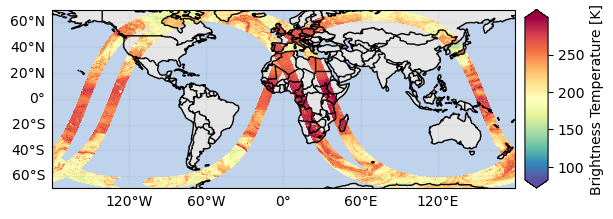

In [ ]:
# Plot all concatenated orbits
da_brightness_temperature.gpm.plot_map(add_swath_lines=False)

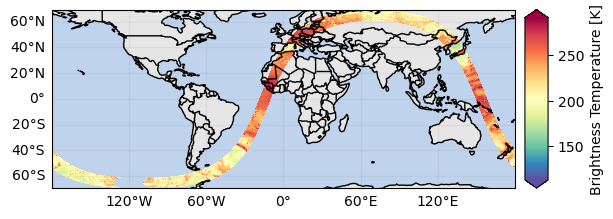

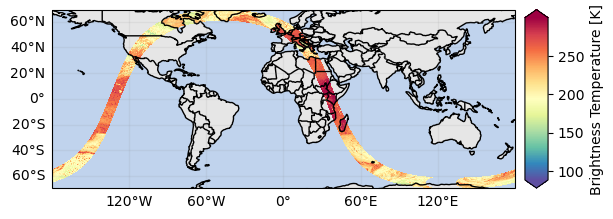

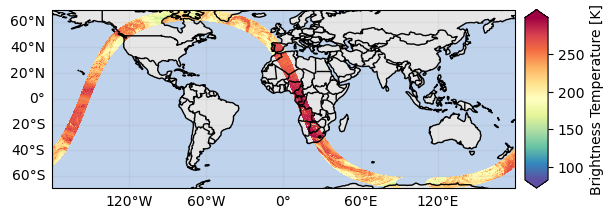

In [ ]:
# Plot one granule at a time
for granule_slice in da_brightness_temperature.gpm.get_slices_granules():
    da_brightness_temperature.isel(along_track=granule_slice).gpm.plot_map(
        add_swath_lines=False,
    )
    plt.show()

Always close the returned object when it is no longer needed:


In [ ]:
dt.close()

## 4. Opening gridded IMERG data

The same workflow applies to gridded products. IMERG is a useful example
because its output is indexed by ``time`` rather than ``along_track``:

In [ ]:
product = "IMERG-FR"
short_name = gpm.get_nasa_collection_shortname(product)
version = "07"

results = earthaccess.search_data(
    short_name=short_name,
    version=version,
    bounding_box=(0, 30, 10, 40),
    temporal=("2017-01-01 10:00", "2017-01-01 11:00"),
)

filepaths = earthaccess.download(results, download_directory)
dt = gpm.open_files(filepaths)
dt

QUEUEING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/3 [00:00<?, ?it/s]

<xarray.DataTree>
Group: /
└── Group: /Grid
        Dimensions:                         (time: 3, lat: 1800, lon: 3600, lonv: 2,
                                             latv: 2, nv: 2)
        Coordinates:
          * time                            (time) datetime64[ns] 24B 2017-01-01T10:3...
          * lat                             (lat) float32 7kB -89.95 -89.85 ... 89.95
            lat_bnds                        (latv, lat) float32 14kB dask.array<chunksize=(2, 1800), meta=np.ndarray>
          * lon                             (lon) float32 14kB -179.9 -179.9 ... 179.9
            lon_bnds                        (lonv, lon) float32 29kB dask.array<chunksize=(2, 3600), meta=np.ndarray>
            time_bnds                       (time, nv) datetime64[ns] 48B 2017-01-01T...
            crsWGS84                        int64 8B 0
        Dimensions without coordinates: lonv, latv, nv
        Data variables:
            precipitation                   (time, lat, lon) float32 78MB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
            randomError                     (time, lat, lon) float32 78MB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
            probabilityLiquidPrecipitation  (time, lat, lon) float32 78MB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
            precipitationQualityIndex       (time, lat, lon) float32 78MB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
            MWprecipitation                 (time, lat, lon) float32 78MB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
            MWprecipSource                  (time, lat, lon) float32 78MB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
            MWobservationTime               (time, lat, lon) float32 78MB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
            IRprecipitation                 (time, lat, lon) float32 78MB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
            IRinfluence                     (time, lat, lon) float32 78MB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
            precipitationUncal              (time, lat, lon) float32 78MB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
        Attributes: (12/15)
            FileName:           3B-HHR.MS.MRG.3IMERG.20170101-S100000-E102959.0600.V0...
            MissingData:        
            DOI:                10.5067/GPM/IMERG/3B-HH/07
            DOIauthority:       http://dx.doi.org/
            AlgorithmID:        3IMERGHH
            AlgorithmVersion:   3IMERGH_7.0
            ...                 ...
            ProcessingSystem:   PPS
            DataFormatVersion:  7e
            MetadataVersion:    7e
            ScanMode:           Grid
            gpm_api_product:    IMERG-FR
            history:            Created by ghiggi/gpm_api software on 2026-11-02 17:3...

In [ ]:
ds = dt["Grid"].to_dataset()
ds

<xarray.Dataset> Size: 778MB
Dimensions:                         (time: 3, lat: 1800, lon: 3600, lonv: 2,
                                     latv: 2, nv: 2)
Coordinates:
  * time                            (time) datetime64[ns] 24B 2017-01-01T10:3...
  * lat                             (lat) float32 7kB -89.95 -89.85 ... 89.95
    lat_bnds                        (latv, lat) float32 14kB dask.array<chunksize=(2, 1800), meta=np.ndarray>
  * lon                             (lon) float32 14kB -179.9 -179.9 ... 179.9
    lon_bnds                        (lonv, lon) float32 29kB dask.array<chunksize=(2, 3600), meta=np.ndarray>
    time_bnds                       (time, nv) datetime64[ns] 48B 2017-01-01T...
    crsWGS84                        int64 8B 0
Dimensions without coordinates: lonv, latv, nv
Data variables:
    precipitation                   (time, lat, lon) float32 78MB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
    randomError                     (time, lat, lon) float32 78MB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
    probabilityLiquidPrecipitation  (time, lat, lon) float32 78MB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
    precipitationQualityIndex       (time, lat, lon) float32 78MB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
    MWprecipitation                 (time, lat, lon) float32 78MB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
    MWprecipSource                  (time, lat, lon) float32 78MB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
    MWobservationTime               (time, lat, lon) float32 78MB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
    IRprecipitation                 (time, lat, lon) float32 78MB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
    IRinfluence                     (time, lat, lon) float32 78MB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
    precipitationUncal              (time, lat, lon) float32 78MB dask.array<chunksize=(1, 1800, 3600), meta=np.ndarray>
Attributes: (12/15)
    FileName:           3B-HHR.MS.MRG.3IMERG.20170101-S100000-E102959.0600.V0...
    MissingData:        
    DOI:                10.5067/GPM/IMERG/3B-HH/07
    DOIauthority:       http://dx.doi.org/
    AlgorithmID:        3IMERGHH
    AlgorithmVersion:   3IMERGH_7.0
    ...                 ...
    ProcessingSystem:   PPS
    DataFormatVersion:  7e
    MetadataVersion:    7e
    ScanMode:           Grid
    gpm_api_product:    IMERG-FR
    history:            Created by ghiggi/gpm_api software on 2026-11-02 17:3...

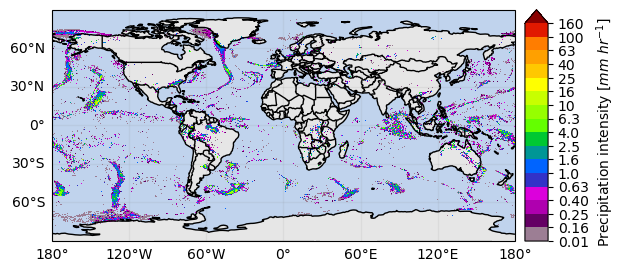

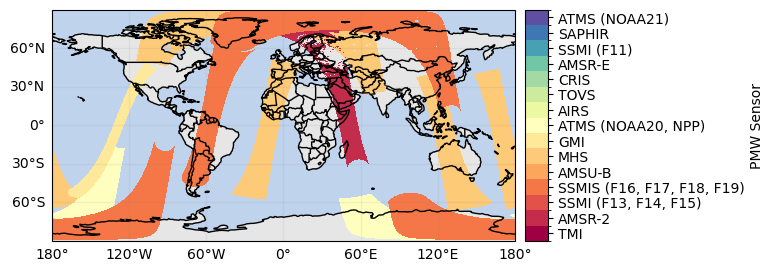

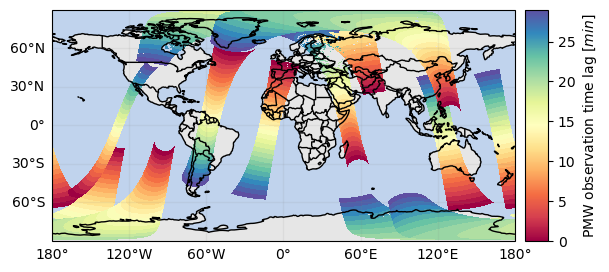

In [ ]:
ds["precipitation"].isel(time=0).gpm.plot_map()
ds["MWprecipSource"].isel(time=0).gpm.plot_map()
ds["MWobservationTime"].isel(time=0).gpm.plot_map()

dt.close()

## 5. Stream files directly from the cloud

EarthAccess can also return file-like objects instead of downloading files.
Pass these objects directly to `gpm.open_files`.

QUEUEING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/3 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/3 [00:00<?, ?it/s]

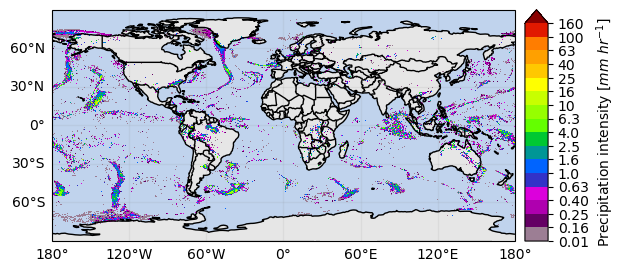

In [ ]:
product = "IMERG-FR"
short_name = gpm.get_nasa_collection_shortname(product)

results = earthaccess.search_data(
    short_name=short_name,
    version="07",
    temporal=("2017-01-01 10:00", "2017-01-01 11:00"),
)

# Each item in files is an EarthAccessFile backed by a remote HTTP object.
files = earthaccess.open(results, open_kwargs={})

# GPM-API automatically uses the h5netcdf backend for non-local sources.
dt = gpm.open_files(files)
ds = dt["Grid"].to_dataset()

# Data remain lazy until explicitly computed.
ds["precipitation"].isel(time=0).gpm.plot_map()

In [ ]:
# Materialize the result only when local in-memory data are required.
dt = dt.compute()
dt

<xarray.DataTree>
Group: /
└── Group: /Grid
        Dimensions:                         (time: 3, lat: 1800, lon: 3600, lonv: 2,
                                             latv: 2, nv: 2)
        Coordinates:
          * time                            (time) datetime64[ns] 24B 2017-01-01T10:3...
          * lat                             (lat) float32 7kB -89.95 -89.85 ... 89.95
            lat_bnds                        (latv, lat) float32 14kB -90.0 ... 90.0
          * lon                             (lon) float32 14kB -179.9 -179.9 ... 179.9
            lon_bnds                        (lonv, lon) float32 29kB -180.0 ... 180.0
            time_bnds                       (time, nv) datetime64[ns] 48B 2017-01-01T...
            crsWGS84                        int64 8B 0
        Dimensions without coordinates: lonv, latv, nv
        Data variables:
            precipitation                   (time, lat, lon) float32 78MB nan ... 0.0
            randomError                     (time, lat, lon) float32 78MB nan ... 0.24
            probabilityLiquidPrecipitation  (time, lat, lon) float32 78MB 0.0 ... 0.0
            precipitationQualityIndex       (time, lat, lon) float32 78MB nan ... 0.001
            MWprecipitation                 (time, lat, lon) float32 78MB nan ... nan
            MWprecipSource                  (time, lat, lon) float32 78MB 0.0 ... 0.0
            MWobservationTime               (time, lat, lon) float32 78MB nan ... nan
            IRprecipitation                 (time, lat, lon) float32 78MB nan ... nan
            IRinfluence                     (time, lat, lon) float32 78MB nan ... nan
            precipitationUncal              (time, lat, lon) float32 78MB nan ... 0.0
        Attributes: (12/15)
            FileName:           3B-HHR.MS.MRG.3IMERG.20170101-S100000-E102959.0600.V0...
            MissingData:        
            DOI:                10.5067/GPM/IMERG/3B-HH/07
            DOIauthority:       http://dx.doi.org/
            AlgorithmID:        3IMERGHH
            AlgorithmVersion:   3IMERGH_7.0
            ...                 ...
            ProcessingSystem:   PPS
            DataFormatVersion:  7e
            MetadataVersion:    7e
            ScanMode:           Grid
            gpm_api_product:    IMERG-FR
            history:            Created by ghiggi/gpm_api software on 2026-11-02 17:3...

In [ ]:
dt.close()

## 6. Streaming notes


* A streamed file remains open while the returned ``DataTree`` is in use.
  Close the ``DataTree`` after analysis.
* Streaming inputs are not compatible with ``parallel=True`` in
  `gpm.open_files`.
* The bounding box limits the search results but does not subset the spatial
  extent of each granule. Apply GPM-API spatial subsetting after opening the
  data if needed.
* Use the download workflow when repeated access, offline work, or reproducible
  local inputs are more important than avoiding local storage.